In [ ]:
# PROJETO PROFISSIONAL DE ANÁLISE DE DADOS
## 1. Problema
## 2. Pergunta principal
## 3. Objetivos
## 4. Importação das bibliotecas
## 5. Carregamento dos dados
## 6. Conhecendo a base
## 7. Análise 1
## 8. Análise 2
## 9. Análise 3
## 10. Análise 4
## 11. Análise 5
## 12. Gráficos exploratórios
## 13. Principais descobertas
## 14. Primeiros insights

In [ ]:
## 1. Problema
##As epizootias em primatas são um alerta precoce da epizootias, mas é difícil enxergar onde e quando elas se concentram ao longo dos anos.

In [ ]:
## 2. Pergunta principal
##Como o número de epizootias em PNH mudou ao longo dos anos e quais regiões concentraram os picos?

In [ ]:
## 3. Objetivos
##Analisar a evolução do número de epizootias em primatas não humanos ao longo dos anos e identificar as regiões que concentraram os picos de ocorrência.

In [ ]:
## 4. Importação das bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
## 5. Carregamento dos dados
dados = pd.read_csv("dados_tratados.csv")

In [ ]:
## 6. Conhecendo a base
dados.head()

,ID,MACRORREG_OCOR,COD_UF_OCOR,UF_OCOR,COD_MUN_OCOR,MUN_OCOR,DATA_OCOR,SE_OCOR,MES_OCOR,ANO_OCOR,MONITORAMENTO_OCOR
0,1,CO,52,GO,521100,ITAPIRAPUÃ,NaN,NaN,2.0,2000,1999/2000
1,2,CO,52,GO,521970,SANTA TEREZINHA DE GOIÁS,NaN,NaN,NaN,2000,1999/2000
2,3,CO,52,GO,521520,NOVO BRASIL,NaN,NaN,2.0,2000,1999/2000
3,4,SE,31,MG,310450,ARINOS,NaN,NaN,2.0,2000,1999/2000
4,5,SE,31,MG,310820,BONFINÓPOLIS DE MINAS,NaN,NaN,4.0,2000,1999/2000


In [ ]:
###Conferindo últimos registros
dados.tail()

,ID,MACRORREG_OCOR,COD_UF_OCOR,UF_OCOR,COD_MUN_OCOR,MUN_OCOR,DATA_OCOR,SE_OCOR,MES_OCOR,ANO_OCOR,MONITORAMENTO_OCOR
2632,2633,SE,31,MG,315445,RIACHINHO,2026-05-09,18.0,5.0,2026,2025/2026
2633,2634,SE,31,MG,310450,ARINOS,2026-05-11,19.0,5.0,2026,2025/2026
2634,2635,SE,31,MG,317040,UNAÍ,2026-05-13,19.0,5.0,2026,2025/2026
2635,2636,SE,31,MG,317052,URUCUIA,2026-05-11,19.0,5.0,2026,2025/2026
2636,2637,SE,35,SP,354780,SANTO ANDRÉ,2026-05-06,18.0,5.0,2026,2025/2026


In [ ]:
###Verificando o banco de dados
dados.shape

(2637, 11)

In [ ]:
###Verificando os tipos
dados.dtypes

,0
ID,int64
MACRORREG_OCOR,object
COD_UF_OCOR,int64
UF_OCOR,object
COD_MUN_OCOR,int64
MUN_OCOR,object
DATA_OCOR,object
SE_OCOR,float64
MES_OCOR,float64
ANO_OCOR,int64


In [ ]:
###Verificando as colunas
dados.columns

Index(['ID', 'MACRORREG_OCOR', 'COD_UF_OCOR', 'UF_OCOR', 'COD_MUN_OCOR',
       'MUN_OCOR', 'DATA_OCOR', 'SE_OCOR', 'MES_OCOR', 'ANO_OCOR',
       'MONITORAMENTO_OCOR'],
      dtype='object')

In [ ]:
###Verificando as ifnromações gerais
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  2637 non-null   int64  
 1   MACRORREG_OCOR      2637 non-null   object 
 2   COD_UF_OCOR         2637 non-null   int64  
 3   UF_OCOR             2637 non-null   object 
 4   COD_MUN_OCOR        2637 non-null   int64  
 5   MUN_OCOR            2637 non-null   object 
 6   DATA_OCOR           2615 non-null   object 
 7   SE_OCOR             2615 non-null   float64
 8   MES_OCOR            2624 non-null   float64
 9   ANO_OCOR            2637 non-null   int64  
 10  MONITORAMENTO_OCOR  2637 non-null   object 
dtypes: float64(2), int64(4), object(5)
memory usage: 226.7+ KB


In [ ]:
####Quantos registros temos
len(dados)

2637

In [ ]:
## 7. Análise 1
#Pergunta 1: qual UF apresenta maior quantidade de registros?
dados["UF_OCOR"].value_counts()

,count
UF_OCOR,
SP,941
PR,399
MG,318
RS,307
SC,254
GO,111
RJ,91
ES,81
BA,48


In [ ]:
## 8. Análise 2
#Pergunta 2: qual município apresenta maior quantidade de registros?
top_municipios = dados["MUN_OCOR"].value_counts().head(5)
top_municipios

,count
MUN_OCOR,
SÃO PAULO,115
MAIRIPORÃ,98
JUNDIAÍ,68
BRAGANÇA PAULISTA,54
ITAPECERICA DA SERRA,52


In [ ]:
## 9. Análise 3
#Pergunta 3: qual período apresenta maior quantidade de registros (por ano)?
dados["DATA_OCOR"] = pd.to_datetime(dados["DATA_OCOR"])

In [ ]:
#Periodo que apresenta menor quantidade
dados["DATA_OCOR"].min()

Timestamp('2002-11-14 00:00:00')

In [ ]:
#Periodo que apresenta maior quantidade
dados["DATA_OCOR"].max()

Timestamp('2026-05-13 00:00:00')

In [ ]:
## 10. Análise 4
#Pergunta 4: qual mês apresenta maior quantidade de registros?
dados["MES_OCOR"].value_counts().sort_index()

,count
MES_OCOR,
1.0,562
2.0,423
3.0,340
4.0,325
5.0,110
6.0,40
7.0,49
8.0,33
9.0,107


In [ ]:
## 11. Análise 5
#Pergunta 5: existem valores muito diferentes dos demais?
contagem_municipios = dados["MUN_OCOR"].value_counts()
contagem_municipios.describe()

,count
count,630.000000
mean,4.185714
std,8.852193
min,1.000000
25%,1.000000
50%,2.000000
75%,4.000000
max,115.000000


In [ ]:
###Conferindo média e mediana
media = contagem_municipios.mean()
mediana = contagem_municipios.median()
print("Média:", media)
print("Mediana:", mediana)

Média: 4.185714285714286
Mediana: 2.0


## 12. Gráficos exploratórios


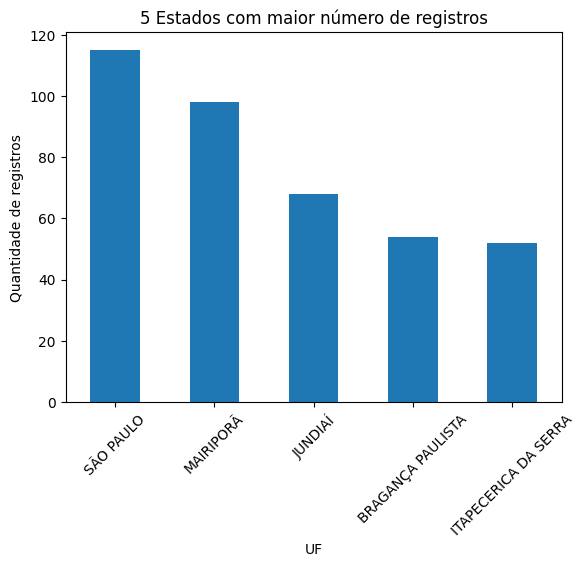

In [ ]:
#5 Estado com maiores registros
top_municipios.plot(kind="bar")
plt.title("5 Estados com maior número de registros")
plt.xlabel("UF")
plt.ylabel("Quantidade de registros")
plt.xticks(rotation=45)
plt.show()

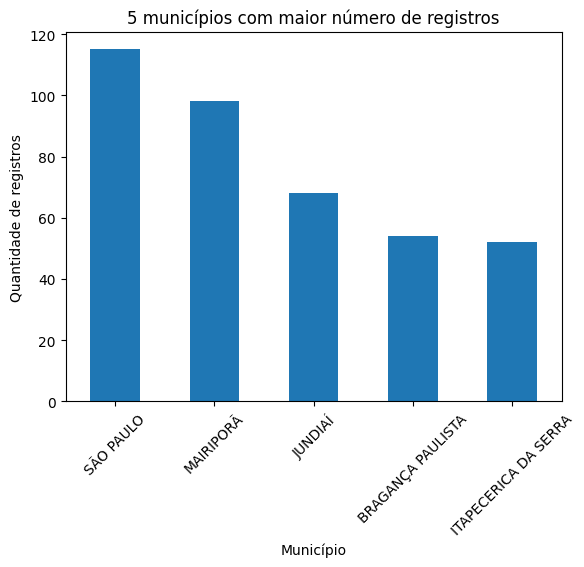

In [ ]:
#5 municípios com maior número de registros
top_municipios.plot(kind="bar")
plt.title("5 municípios com maior número de registros")
plt.xlabel("Município")
plt.ylabel("Quantidade de registros")
plt.xticks(rotation=45)
plt.show()

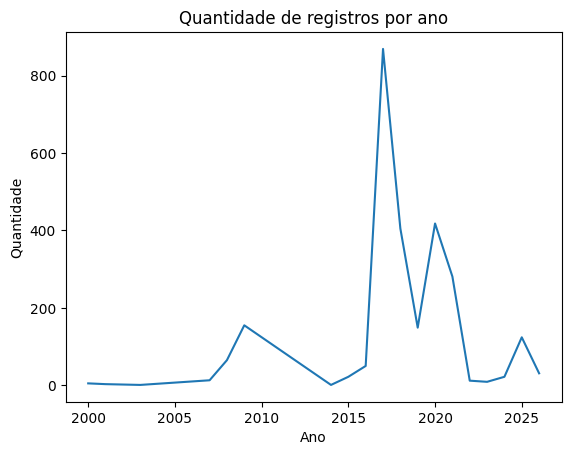

In [ ]:
#Quantidade de registros por ano
dados["ANO_OCOR"].value_counts().sort_index().plot(kind="line")
plt.title("Quantidade de registros por ano")
plt.xlabel("Ano")
plt.ylabel("Quantidade")
plt.show()

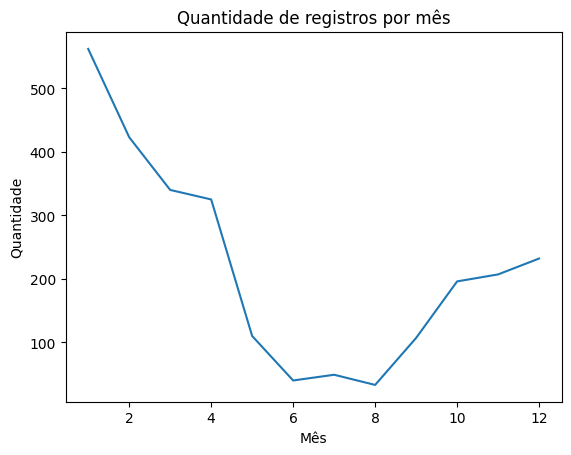

In [ ]:
#Quantidade de registros por mês
dados["MES_OCOR"].value_counts().sort_index().plot(kind="line")
plt.title("Quantidade de registros por mês")
plt.xlabel("Mês")
plt.ylabel("Quantidade")
plt.show()

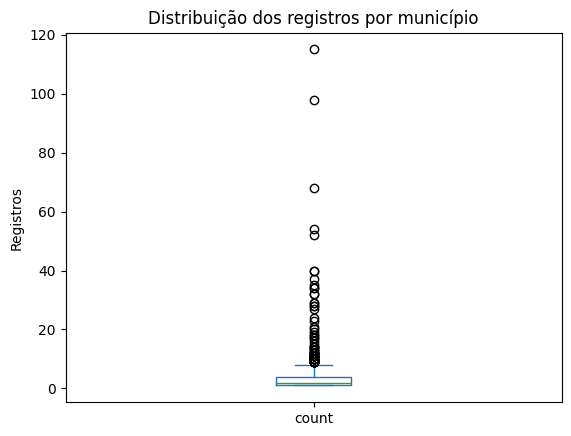

In [ ]:
#Boxplot: registros por município
contagem_municipios.plot(kind="box")
plt.title("Distribuição dos registros por município")
plt.ylabel("Registros")
plt.show()

In [ ]:
## 13. Principais descobertas
# O Estado com maiores registros é São Paulo
# O município com maiores registros é São Paulo
# O ano que obteve maiores registros se concentra entre 2015 e 2020
# O mês com maior frequência de casos se concentra entre Outubro e Abril, com declínio entre Maio e crescimento em Agosto
#É possível notar uma distribuição igual entre os Municípios, por meio do gráfio "Distribuição dos registros por município", com o único que se
#destaca sendo São Paulo

In [ ]:
## 14. Primeiros insights
#O comportamento ao longo dos anos parece ser de picos pontuais e não de crescimento contínuo
#Existe um padrão sazonal, com concentração no começo do ano

In [ ]:
##O que os dados estão mostrando?
#Os dados estão mostrando como a epizootias se comportou no decorrer das decadas de 2000 à 2026 para com os primatas não humanos,
#dessa forma, nossa equipe entendeu quais locais ela se tornou mais presente e por meio disso, possamos compreender essa diferença

#Insights do projeto - Aula 6

###Etapa 3 — Selecionar cinco resultados
- O Estado com maiores registros é São Paulo
- O município com maiores registros é São Paulo
- O ano que obteve maiores registros se concentra entre 2015 e 2020
- O mês com maior frequência de casos se concentra entre Outubro e Abril, com declínio entre Maio e crescimento em Agosto
- É possível notar uma distribuição igual entre os Municípios, por meio do gráfio "Distribuição dos registros por município", com o único que se destaca sendo São Paulo

###Etapa 4 — Aprofundar

###Resultado escolhida:
### "O ano que obteve maiores registros se concentra entre 2015 e 2020"

###Nova pergunta: o ano de pico está muito acima do segundo ano com mais registros?

In [ ]:
por_ano = (
    dados.groupby("ANO_OCOR")["ID"]
    .count()
)

por_ano

,ID
ANO_OCOR,
2000,5
2001,3
2002,2
2003,1
2007,13
2008,65
2009,155
2014,1
2015,22


###Resultados escolhidos:
### "É possível notar uma distribuição igual entre os Municípios, por meio do gráfio "Distribuição dos registros por município", com o único que se destaca sendo São Paulo"
###"O Estado com maiores registros é São Paulo"
###Nova pergunta: os picos ocorreram na mesma macrorregião?

In [ ]:
dados.groupby(
    ["ANO_OCOR", "MACRORREG_OCOR"]
)["ID"].count()

ANO_OCOR  MACRORREG_OCOR
2000      CO                  3
          SE                  2
2001      S                   2
          SE                  1
2002      S                   1
          SE                  1
2003      S                   1
2007      CO                 13
2008      CO                 18
          N                   1
          S                  35
          SE                 11
2009      S                 152
          SE                  3
2014      N                   1
2015      CO                 12
          N                   6
          SE                  4
2016      CO                 15
          SE                 35
2017      CO                 12
          N                  28
          NE                 48
          SE                781
2018      CO                  2
          N                   3
          SE                400
2019      CO                  2
          N                   1
          S                 127
          SE                 19
2020      CO                 29
          S                 385
          SE                  4
2021      CO                  4
          N                   3
          S                 249
          SE                 25
2022      N                   1
          S                   1
          SE                 10
2023      S                   8
          SE                  1
2024      N                   4
          SE                 18
2025      CO                 38
          SE                 86
2026      N                   1
          SE                 30
Name: ID, dtype: int64

###Resultado escolhido:
### "É possível notar uma distribuição igual entre os Municípios, por meio do gráfio "Distribuição dos registros por município", com o único que se destaca sendo São Paulo"
###Nova pergunta: a diferença entre a macrorregião e o estado líderes e os segundos colocados é grande?

In [ ]:
macro = (
    dados.groupby("MACRORREG_OCOR")["ID"]
    .count()
    .sort_values(ascending=False)
)

macro

,ID
MACRORREG_OCOR,
SE,1431
S,961
CO,148
N,49
NE,48


###Resultado escolhido:
###"O município com maiores registros é São Paulo"
###Nova pergunta: São Paulo tem mais registros porque tem mais população ou porque a taxa de registros é maior?

In [ ]:
analise = (
    dados.groupby("MUN_OCOR")["ID"]
    .agg(["count"])
    .sort_values("count", ascending=False)
)

analise.head(10)

,count
MUN_OCOR,
SÃO PAULO,115
MAIRIPORÃ,98
JUNDIAÍ,68
BRAGANÇA PAULISTA,54
ITAPECERICA DA SERRA,52
GOIÂNIA,40
ATIBAIA,40
CASTRO,37
SÃO MATEUS DO SUL,35


###Conclusão para essa pergunta nova:
###a base não possui dados de população, então ela não possui dados suficientes para responder a essa pergunta. Isso fica registrado como limitação.

###Resultados selecionados:
###"O ano que obteve maiores registros se concentra entre 2015 e 2020"
###"O mês com maior frequência de casos se concentra entre Outubro e Abril, com declínio entre Maio e crescimento em Agosto"
###Nova pergunta: o padrão por mês se repete ao longo dos anos ou só aparece nos anos de pico?

In [ ]:
meses = dados["MES_OCOR"].value_counts().sort_values(ascending=False)

meses

,count
MES_OCOR,
1.0,562
2.0,423
3.0,340
4.0,325
12.0,232
11.0,207
10.0,196
5.0,110
9.0,107


In [ ]:
insights = pd.DataFrame({
    "pergunta": [
        "Qual foi o ano de pico?",
        "Quais regiões concentraram os picos?",
        "Qual macrorregião e estado lideram?",
        "Quais municípios têm mais registros?",
        "Quais meses têm mais registros?"
    ],
    "resultado": [
        "Aparentasse ser no ano de 2017 com 869 registros",
        "Picos alternam entre Sergipe e São Paulo",
        "Sergipe (1.431) e São Paulo (941) lideram",
        "São Paulo (115) e Mairiporã (98)",
        "O mês de Janeiro lidera (562)"
    ],
    "relevancia": ["Alta", "Alta", "Média", "Baixa", "Alta"]
})

insights

,pergunta,resultado,relevancia
0,Qual foi o ano de pico?,2017 com 869 registros,Alta
1,Quais regiões concentraram os picos?,Picos alternam entre SE e S,Alta
2,Qual macrorregião e estado lideram?,SE (1.431) e SP (941) lideram,Média
3,Quais municípios têm mais registros?,São Paulo (115) e Mairiporã (98),Baixa
4,Quais meses têm mais registros?,Janeiro lidera (562),Alta


###ETAPA 6 — CRIAR UMA CONCLUSÃO PARA CADA INSIGHT

Insight 1. Os dados mostram que 2017 foi o ano de pico, com 869 registros. Esse resultado é relevante porque responde como o número de epizootias mudou ao longo dos anos. A análise indica que a evolução ocorre em picos pontuais, e não em crescimento contínuo.

Insight 2. Os dados mostram que cada pico se concentrou em uma macrorregião: Sergipe em 2017, com 781 de 869 e 2018 com 400, e São Paualo em 2008–2009 e 2019–2021. Esse resultado é relevante porque responde quais regiões concentraram os picos. A análise indica que os picos alternam entre Sul e Sudeste.

Insight 3: A atividade registrada se concentra no Sudeste e no Sul, com SP na liderança

Insight 4: Há concentração em poucos municípios, mas a base não tem população para calcular taxas

Insight 5. Os dados mostram que janeiro é o mês com mais registros (562) e que junho a agosto têm menos de 50 cada, padrão que também aparece nos anos de pico. Esse resultado é relevante porque mostra quando as epizootias se concentram. A análise indica sazonalidade, e isso deverá ser apresentado no Dashboard.

###ETAPA 7 — IDENTIFICAR LIMITAÇÕES

- A base registra epizootias notificadas, não a ocorrência real.
- A base não tem população nem área dos municípios e estados, então não permite calcular taxas por habitante nem explicar se uma região tem mais registros por ter mais população.
- A base não tem fatores bióticos ou abióticos, então não permite afirmar causas dos picos.
- Não há registros em 2004–2006 e 2010–2013, o que afeta a leitura da variação percentual entre anos.
- 2026 vai só até 13/05/2026, então é um ano parcial.
- Poucos registros no Norte (49) e no Nordeste (48) podem refletir menos notificação, e os dados não permitem saber.